# Baseline and data exploration: Fashion-MNIST

Fashion-MNIST has 60,000 training and 10,000 test images of clothing (28 x 28, grey) in 10 classes. It is our main dataset.

This notebook looks at the data itself (classes, examples, how we split it across 10 clients and how non-IID each split is) and at the classical CNN trained with FedAvg, which is the reference for every hybrid result. The figures are saved to `results/plots`. The model results are in `plot_results_fashionmnist.ipynb`.

In [1]:
import io
import os
import sys
import contextlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import MaxNLocator

sys.path.insert(0, os.path.abspath(".."))
from data import load_dataset, get_labels, iid_partition, dirichlet_partition, compute_emd_proxy

%matplotlib inline

In [2]:
DATASET    = "fashionmnist"
TABLES_DIR = os.path.join("../results/tables", "")
PLOTS_DIR  = os.path.join("../results/plots", "")
CLASSES    = ["T-shirt", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

SPLITS = {"IID": ("iid", None), "Dirichlet α=0.5": ("dirichlet", 0.5), "Dirichlet α=0.1": ("dirichlet", 0.1)}
SKEW_COLORS = {"IID": "#86b6ef", "Dirichlet α=0.5": "#2a78d6", "Dirichlet α=0.1": "#104281"}
BLUES = LinearSegmentedColormap.from_list("blues", ["#f3f7fd", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
INK = "#52514e"

os.makedirs(PLOTS_DIR, exist_ok=True)

## 1. The dataset

Number of images per class in the training and test sets.

In [3]:
train, test = load_dataset(DATASET)
y_train, y_test = get_labels(train), get_labels(test)
images = train.data.numpy() if hasattr(train, "data") else train.imgs   # raw pixels, 0 to 255

counts = pd.DataFrame({
    "class": CLASSES,
    "train images": np.bincount(y_train, minlength=len(CLASSES)),
    "test images": np.bincount(y_test, minlength=len(CLASSES)),
})
counts["train share (%)"] = (counts["train images"] / len(y_train) * 100).round(1)
counts["test share (%)"] = (counts["test images"] / len(y_test) * 100).round(1)
print(f"{len(y_train):,} training and {len(y_test):,} test images, image shape {tuple(images.shape[1:])}, {len(CLASSES)} classes")
counts

[data] fashionmnist: 60000 train / 10000 test
60,000 training and 10,000 test images, image shape (28, 28), 10 classes


,class,train images,test images,train share (%),test share (%)
0,T-shirt,6000,1000,10.0,10.0
1,Trouser,6000,1000,10.0,10.0
2,Pullover,6000,1000,10.0,10.0
3,Dress,6000,1000,10.0,10.0
4,Coat,6000,1000,10.0,10.0
5,Sandal,6000,1000,10.0,10.0
6,Shirt,6000,1000,10.0,10.0
7,Sneaker,6000,1000,10.0,10.0
8,Bag,6000,1000,10.0,10.0
9,Ankle boot,6000,1000,10.0,10.0


Class balance. The dashed line is an equal share for every class.

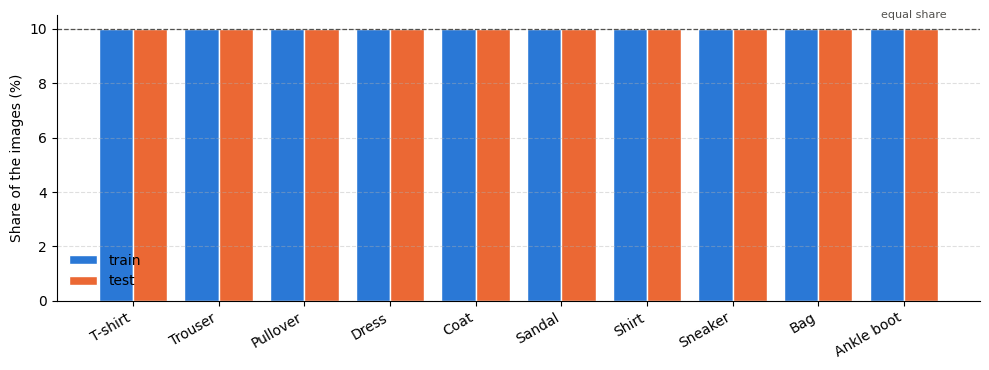

Saved: ../results/plots\class_balance.png


In [4]:
x = np.arange(len(CLASSES))
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(x - 0.2, counts["train share (%)"], 0.4, color="#2a78d6", edgecolor="white", label="train")
ax.bar(x + 0.2, counts["test share (%)"], 0.4, color="#eb6834", edgecolor="white", label="test")
ax.axhline(100 / len(CLASSES), color=INK, ls="--", lw=0.9)
ax.text(len(CLASSES) - 0.5, 100 / len(CLASSES) + 0.4, "equal share", ha="right", fontsize=8, color=INK)
ax.set_xticks(x)
ax.set_xticklabels(CLASSES, rotation=30, ha="right")
ax.set_ylabel("Share of the images (%)")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", ls="--", alpha=0.4)
ax.legend(frameon=False)
fig.tight_layout()

out = os.path.join(PLOTS_DIR, "class_balance.png")
fig.savefig(out, dpi=200)
plt.show()
print(f"Saved: {out}")

Eight random training images of every class:

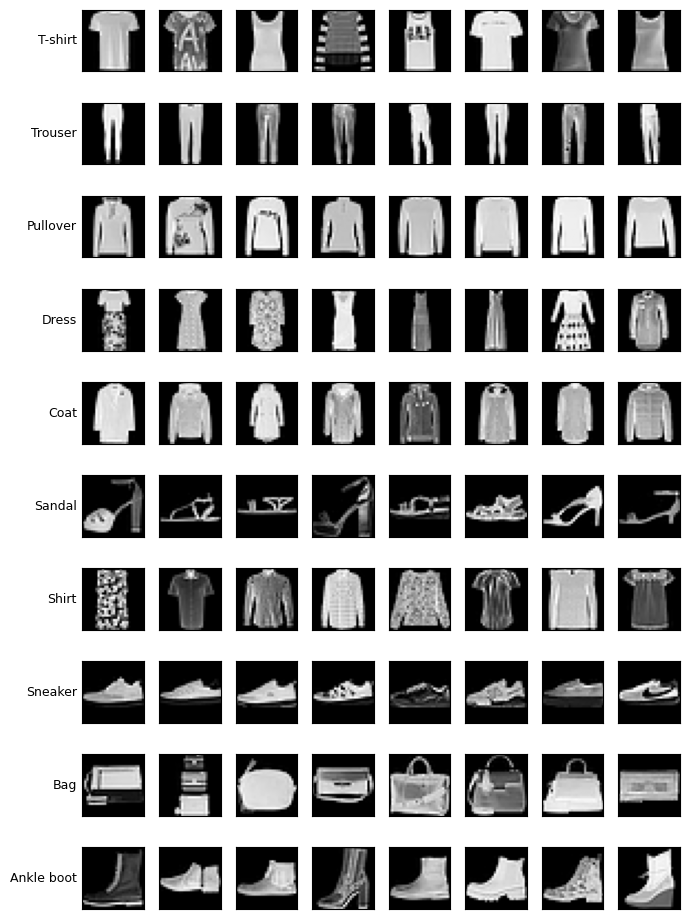

Saved: ../results/plots\samples.png


In [5]:
rng = np.random.default_rng(0)
fig, axes = plt.subplots(len(CLASSES), 8, figsize=(7, len(CLASSES) * 0.95))
for c, name in enumerate(CLASSES):
    picks = rng.choice(np.where(y_train == c)[0], 8, replace=False)
    for j, i in enumerate(picks):
        axes[c, j].imshow(images[i], cmap="gray" if images.ndim == 3 else None)
        axes[c, j].set_xticks([])
        axes[c, j].set_yticks([])
    axes[c, 0].set_ylabel(name, rotation=0, ha="right", va="center", fontsize=9)
fig.tight_layout()

out = os.path.join(PLOTS_DIR, "samples.png")
fig.savefig(out, dpi=200)
plt.show()
print(f"Saved: {out}")

The average image of every class, and the pixel statistics (pixels scaled to 0 to 1 here; the models see them normalised to −1 to 1):

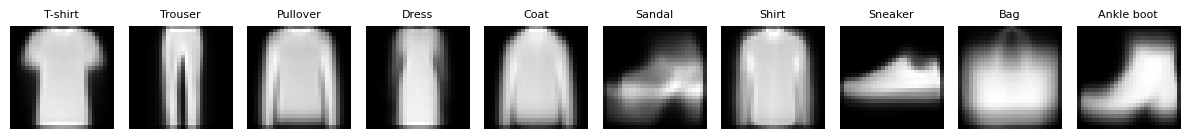

Saved: ../results/plots\class_means.png
pixel mean per channel: [0.286] | pixel std per channel: [0.353]


In [6]:
fig, axes = plt.subplots(1, len(CLASSES), figsize=(len(CLASSES) * 1.2, 1.7))
for c, name in enumerate(CLASSES):
    mean_image = images[y_train == c].mean(axis=0)
    axes[c].imshow(mean_image.astype(np.uint8), cmap="gray" if images.ndim == 3 else None)
    axes[c].set_title(name, fontsize=8)
    axes[c].axis("off")
fig.tight_layout()

out = os.path.join(PLOTS_DIR, "class_means.png")
fig.savefig(out, dpi=200)
plt.show()
print(f"Saved: {out}")

pixels = images.reshape(len(images), -1, 1 if images.ndim == 3 else 3) / 255
print("pixel mean per channel:", pixels.mean(axis=(0, 1)).round(3), "| pixel std per channel:", pixels.std(axis=(0, 1)).round(3))

## 2. How the data is split across 10 clients

Each row is one client (its number of images in brackets) and each column one class; the colour is the share of that client's images that belong to the class. With IID every client has every class; with Dirichlet α = 0.1 most clients hold only one to three classes. The EMD is the measured non-IID level (0 = all clients have the same class mix, 2 = no two clients share a class). Seed 42.

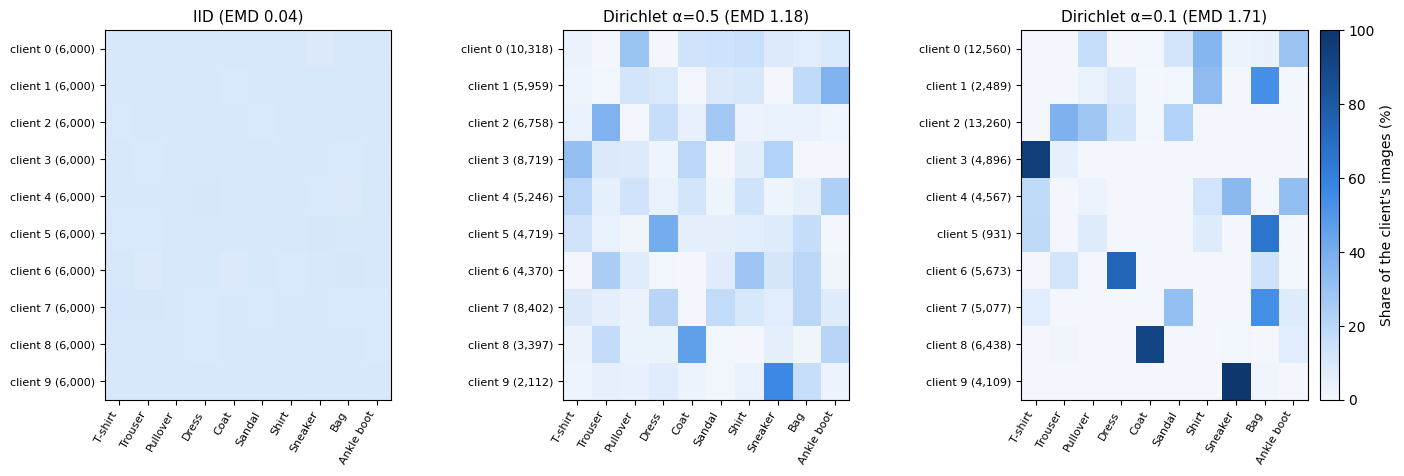

Saved: ../results/plots\client_splits.png


In [7]:
splits = {}
for name, (kind, alpha) in SPLITS.items():
    with contextlib.redirect_stdout(io.StringIO()):   # the partition functions print their own summary
        if kind == "iid":
            idx = iid_partition(train, n_clients=10, seed=42)
        else:
            idx = dirichlet_partition(train, n_clients=10, alpha=alpha, seed=42)
        emd = compute_emd_proxy(idx, train)
    per_client = np.array([np.bincount(y_train[idx[k]], minlength=len(CLASSES)) for k in range(10)])
    splits[name] = (per_client, emd)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), gridspec_kw={"wspace": 0.6})
for ax, (name, (per_client, emd)) in zip(axes, splits.items()):
    share = per_client / per_client.sum(axis=1, keepdims=True) * 100
    im = ax.imshow(share, cmap=BLUES, vmin=0, vmax=100, aspect="auto")
    ax.set_title(f"{name} (EMD {emd:.2f})", fontsize=11)
    ax.set_xticks(range(len(CLASSES)))
    ax.set_xticklabels(CLASSES, rotation=60, ha="right", fontsize=8)
    ax.set_yticks(range(10))
    ax.set_yticklabels([f"client {k} ({n:,})" for k, n in enumerate(per_client.sum(axis=1))], fontsize=8)
cb = fig.colorbar(im, ax=axes, fraction=0.02, pad=0.01)
cb.set_label("Share of the client's images (%)")

out = os.path.join(PLOTS_DIR, "client_splits.png")
fig.savefig(out, dpi=200, bbox_inches="tight")
plt.show()
print(f"Saved: {out}")

Measured EMD for different Dirichlet α (mean ± std over seeds 42 to 49). Smaller α gives more skew; the curve shows how α maps to the measured non-IID level on this dataset.

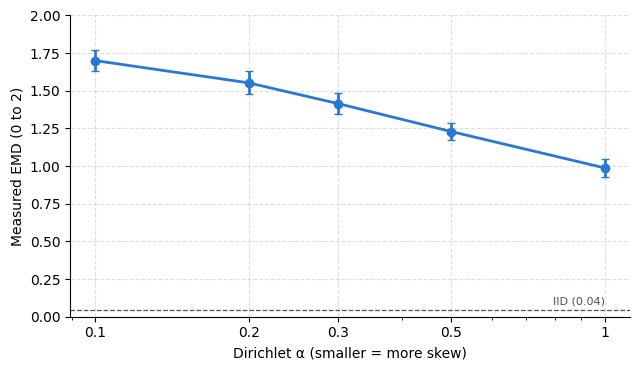

Saved: ../results/plots\emd_vs_alpha.png


,mean,std
alpha,,
1.0,0.988,0.061
0.5,1.229,0.057
0.3,1.415,0.072
0.2,1.553,0.076
0.1,1.700,0.068


In [8]:
alphas = [1.0, 0.5, 0.3, 0.2, 0.1]
rows = []
for alpha in alphas:
    for seed in range(42, 50):
        with contextlib.redirect_stdout(io.StringIO()):
            emd = compute_emd_proxy(dirichlet_partition(train, n_clients=10, alpha=alpha, seed=seed), train)
        rows.append({"alpha": alpha, "seed": seed, "emd": emd})
with contextlib.redirect_stdout(io.StringIO()):
    iid_emd = np.mean([compute_emd_proxy(iid_partition(train, n_clients=10, seed=s), train) for s in range(42, 50)])
emd_table = pd.DataFrame(rows).groupby("alpha")["emd"].agg(["mean", "std"]).sort_index(ascending=False)

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.errorbar(emd_table.index, emd_table["mean"], yerr=emd_table["std"], color="#2a78d6", marker="o", lw=2, capsize=3)
ax.axhline(iid_emd, color=INK, ls="--", lw=0.9)
ax.text(1.0, iid_emd + 0.04, f"IID ({iid_emd:.2f})", ha="right", fontsize=8, color=INK)
ax.set_xscale("log")
ax.set_xticks(alphas)
ax.set_xticklabels([f"{a:g}" for a in alphas])
ax.set_xlabel("Dirichlet α (smaller = more skew)")
ax.set_ylabel("Measured EMD (0 to 2)")
ax.set_ylim(0, 2)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(True, ls="--", alpha=0.4)
fig.tight_layout()

out = os.path.join(PLOTS_DIR, "emd_vs_alpha.png")
fig.savefig(out, dpi=200)
plt.show()
print(f"Saved: {out}")
emd_table.round(3)

## 3. Classical FedAvg baseline

The classical CNN (105,866 parameters) trained with FedAvg on the same splits as the hybrid model: 10 clients, 20 rounds, 1 local epoch, batch size 32, learning rate 0.001. Mean over seeds, the shaded band is ±1 std. Splits that have not been run yet are skipped.

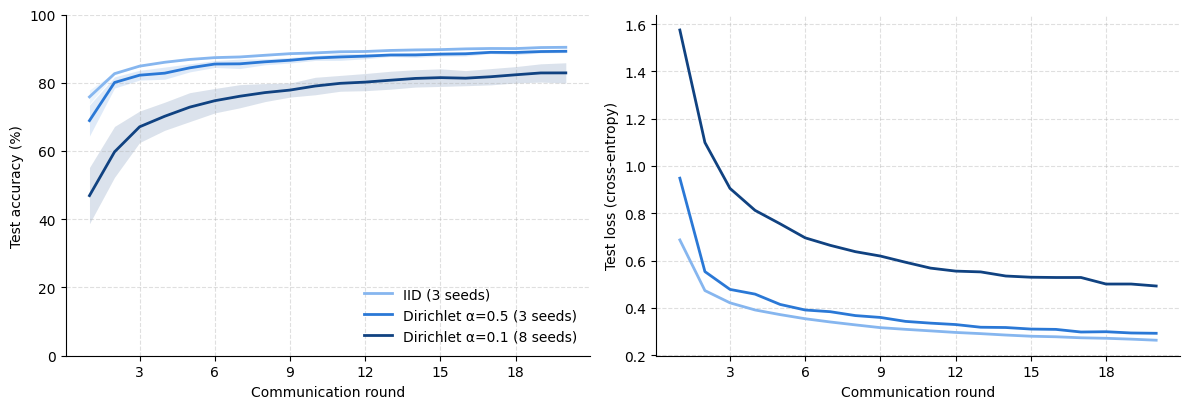

Saved: ../results/plots\classical_baseline.png
Drop from IID to the strongest skew: 7.90 points


,split,seeds,EMD,last-5 accuracy,std
0,IID,3,0.04,90.14,0.22
1,Dirichlet α=0.5,3,1.21,88.93,0.60
2,Dirichlet α=0.1,8,1.70,82.24,2.66


In [9]:
curves, table = {}, []
for name, (kind, alpha) in SPLITS.items():
    tag = "iid_a0.5" if kind == "iid" else f"dirichlet_a{alpha}"
    found = []
    for seed in range(42, 50):
        path = os.path.join(TABLES_DIR, f"classical_{tag}_c10_e1_lr0.001_s{seed}.csv")
        if os.path.exists(path):
            df = pd.read_csv(path)
            if len(df) >= 20:
                found.append(df)
    if not found:
        continue
    acc = np.array([df["accuracy"].values[:20] * 100 for df in found])
    loss = np.array([df["loss"].values[:20] for df in found])
    curves[name] = (acc, loss)
    last5 = acc[:, -5:].mean(axis=1)
    table.append({"split": name, "seeds": len(found), "EMD": np.mean([df["emd"].iloc[0] for df in found]),
                  "last-5 accuracy": last5.mean(), "std": last5.std(ddof=1) if len(found) > 1 else 0.0})

fig, (ax_acc, ax_loss) = plt.subplots(1, 2, figsize=(12, 4.2))
rounds = np.arange(1, 21)
for name, (acc, loss) in curves.items():
    ax_acc.plot(rounds, acc.mean(axis=0), color=SKEW_COLORS[name], lw=2, label=f"{name} ({len(acc)} seeds)")
    ax_acc.fill_between(rounds, acc.mean(axis=0) - acc.std(axis=0), acc.mean(axis=0) + acc.std(axis=0), color=SKEW_COLORS[name], alpha=0.15, lw=0)
    ax_loss.plot(rounds, loss.mean(axis=0), color=SKEW_COLORS[name], lw=2, label=name)
ax_acc.set_ylim(0, 100)
ax_acc.set_ylabel("Test accuracy (%)")
ax_loss.set_ylabel("Test loss (cross-entropy)")
for ax in (ax_acc, ax_loss):
    ax.set_xlabel("Communication round")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(True, ls="--", alpha=0.4)
ax_acc.legend(frameon=False, loc="lower right")
fig.tight_layout()

out = os.path.join(PLOTS_DIR, "classical_baseline.png")
fig.savefig(out, dpi=200)
plt.show()
print(f"Saved: {out}")

table = pd.DataFrame(table)
if len(table) > 1:
    print(f"Drop from IID to the strongest skew: {table['last-5 accuracy'].iloc[0] - table['last-5 accuracy'].iloc[-1]:.2f} points")
table.round(2)

## 4. The first baseline (September, 3 rounds)

Our very first classical FedAvg runs (10 clients, 3 rounds, before the seed and file-name changes). They are kept as they were, because they were the first sign of the non-IID drop.

In [10]:
import matplotlib.ticker as mticker

configs = {
    "IID (control)":          "classical_iid_a0.5_c10.csv",
    "Dirichlet α=0.5 (moderate skew)": "classical_dirichlet_a0.5_c10.csv",
    "Dirichlet α=0.1 (high skew)":     "classical_dirichlet_a0.1_c10.csv",
}

colors    = list(SKEW_COLORS.values())
linestyles = ["-", "--", ":"]

### Convergence

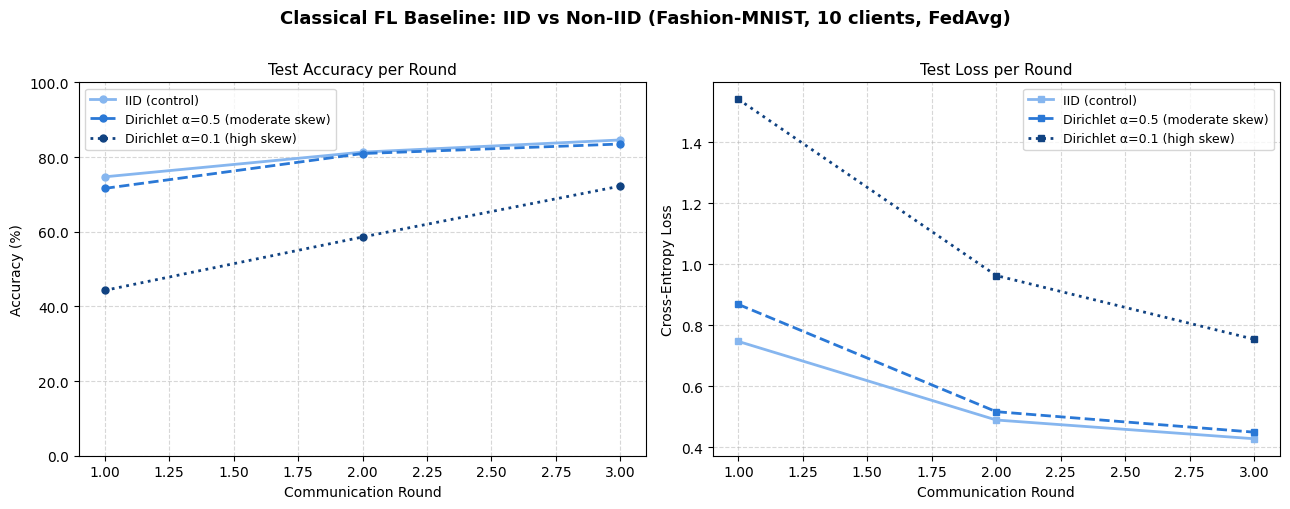

Saved: ../results/plots\baseline_convergence.png


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle("Classical FL Baseline: IID vs Non-IID (Fashion-MNIST, 10 clients, FedAvg)",
             fontsize=13, fontweight="bold", y=1.01)

ax_acc, ax_loss = axes

for (label, fname), color, ls in zip(configs.items(), colors, linestyles):
    path = os.path.join(TABLES_DIR, fname)
    if not os.path.exists(path):
        print(f"Missing: {path}, run the baseline first")
        continue
    df = pd.read_csv(path)
    ax_acc.plot(df["round"], df["accuracy"] * 100, label=label,
                color=color, linestyle=ls, marker="o", linewidth=2, markersize=5)
    ax_loss.plot(df["round"], df["loss"], label=label,
                 color=color, linestyle=ls, marker="s", linewidth=2, markersize=5)

ax_acc.set_title("Test Accuracy per Round", fontsize=11)
ax_acc.set_xlabel("Communication Round")
ax_acc.set_ylabel("Accuracy (%)")
ax_acc.yaxis.set_major_formatter(mticker.FormatStrFormatter("%.1f"))
ax_acc.legend(fontsize=9)
ax_acc.grid(True, linestyle="--", alpha=0.5)
ax_acc.set_ylim(0, 100)

ax_loss.set_title("Test Loss per Round", fontsize=11)
ax_loss.set_xlabel("Communication Round")
ax_loss.set_ylabel("Cross-Entropy Loss")
ax_loss.legend(fontsize=9)
ax_loss.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
out1 = os.path.join(PLOTS_DIR, "baseline_convergence.png")
plt.savefig(out1, dpi=180, bbox_inches="tight")
plt.show()
print(f"Saved: {out1}")

### Final round accuracy

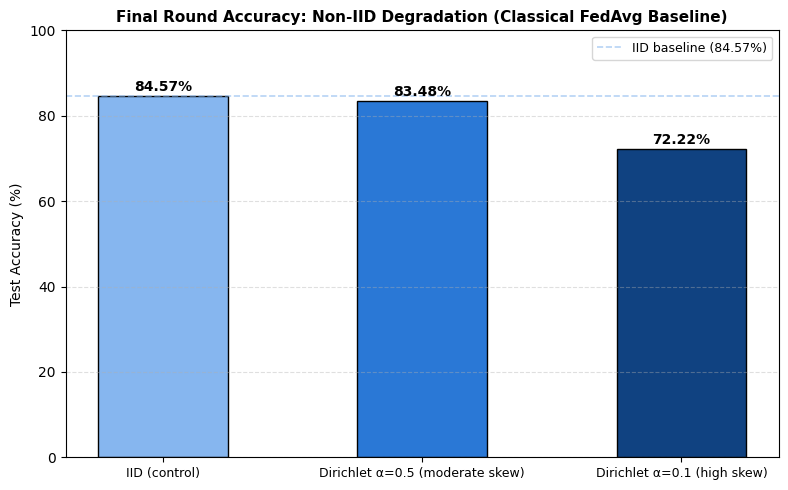

Saved: ../results/plots\baseline_bar_final_acc.png

Non-IID accuracy drop (IID → α=0.1): 12.35%


In [12]:
labels_bar, accs_bar = [], []
for label, fname in configs.items():
    path = os.path.join(TABLES_DIR, fname)
    if not os.path.exists(path):
        continue
    df = pd.read_csv(path)
    labels_bar.append(label)
    accs_bar.append(df["accuracy"].iloc[-1] * 100)

fig2, ax2 = plt.subplots(figsize=(8, 5))
bars = ax2.bar(range(len(labels_bar)), accs_bar, color=colors[:len(labels_bar)],
               edgecolor="black", width=0.5)

for bar, val in zip(bars, accs_bar):
    ax2.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
             f"{val:.2f}%", ha="center", va="bottom", fontweight="bold")

ax2.set_xticks(range(len(labels_bar)))
ax2.set_xticklabels(labels_bar, fontsize=9)
ax2.set_ylabel("Test Accuracy (%)")
ax2.set_title("Final Round Accuracy: Non-IID Degradation (Classical FedAvg Baseline)",
              fontsize=11, fontweight="bold")
ax2.set_ylim(0, 100)
ax2.grid(axis="y", linestyle="--", alpha=0.4)
ax2.axhline(accs_bar[0], color=colors[0], linestyle="--", linewidth=1.2, alpha=0.6,
            label=f"IID baseline ({accs_bar[0]:.2f}%)")
ax2.legend(fontsize=9)

plt.tight_layout()
out2 = os.path.join(PLOTS_DIR, "baseline_bar_final_acc.png")
plt.savefig(out2, dpi=180, bbox_inches="tight")
plt.show()
print(f"Saved: {out2}")

print(f"\nNon-IID accuracy drop (IID → α=0.1): {accs_bar[0] - accs_bar[-1]:.2f}%")